In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "05"

# 05 · Condition 2: it must follow the grid frequency

**Question:** the grid is never exactly at 50 Hz. Does that matter?

A resonant term has high gain only at its exact frequency. A grid at 49.75 Hz moves the 49th order from
2450 Hz to 2438 Hz: 12 Hz away from a fixed resonator, enough to lose it. A frequency-adaptive resonator
is retuned every sample to h × the frequency measured by the PLL.

**Setup.** `sweep.py`, "freq" sweep: SCR 20, full request, grid frequency 49.0-51.0 Hz in 0.25 Hz steps,
adaptive resonators on and off, HIL404 and Virtual HIL.

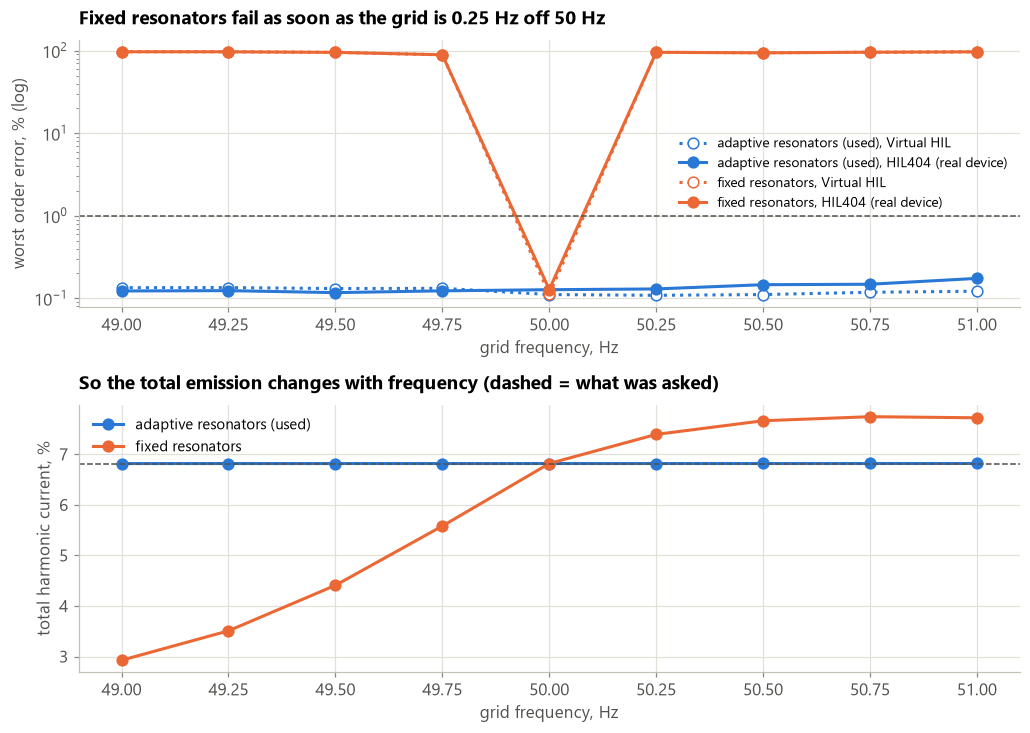

In [2]:
pv, ph = A.load("sweep_vhil_points.csv"), A.load("sweep_hil404_points.csv")
fig, ax = A.panels(2, h=3.4)
for adapt, c, lab in ((True, A.USED, "adaptive resonators (used)"), (False, A.OTHER, "fixed resonators")):
    for dev, p in (("vhil", pv), ("hil404", ph)):
        x = p[(p.sweep == "freq") & (p.adapt == adapt)]
        kw = dict(A.DEVICE[dev]); kw["label"] = "%s, %s" % (lab, kw["label"])
        ax[0].plot(x.f, x.worst_order_error_pct, ls="-" if dev == "hil404" else ":", color=c, **kw)
        if dev == "hil404":
            ax[1].plot(x.f, x.THD_I_pct, "o-", color=c, label=lab)
ax[0].set_yscale("log"); ax[0].axhline(1, color=A.LIMIT, ls="--", lw=1)
ax[0].set_xlabel("grid frequency, Hz"); ax[0].set_ylabel("worst order error, % (log)")
ax[0].set_title("Fixed resonators fail as soon as the grid is 0.25 Hz off 50 Hz")
ax[0].legend(fontsize=9, loc="center right")
ax[1].axhline(np.sqrt((np.array(P.PCT) ** 2).sum()), color=A.LIMIT, ls="--", lw=1)
ax[1].set_xlabel("grid frequency, Hz"); ax[1].set_ylabel("total harmonic current, %")
ax[1].set_title("So the total emission changes with frequency (dashed = what was asked)")
ax[1].legend()
q = ph[ph.sweep == "freq"]
A.save(fig, "05_frequency", q[["f", "adapt", "worst_order_error_pct", "worst_order", "THD_I_pct"]])
fx = q[(~q.adapt) & (q.f != 50.0)]; ad = q[q.adapt]
claim("C5.1", "Adaptive resonators, 49-51 Hz (HIL404): worst order error at most", "%.2f %%" % ad.worst_order_error_pct.max(), "results/sweep_hil404_points.csv (sweep 'freq')")
claim("C5.2", "Fixed resonators, any frequency 0.25 Hz or more off 50 Hz (HIL404): worst order error",
      "%.0f-%.0f %%" % (fx.worst_order_error_pct.min(), fx.worst_order_error_pct.max()), "same file")
claim("C5.3", "Fixed resonators: delivered total harmonic current ranges from (49 Hz) to (51 Hz)",
      "%.1f %% to %.1f %% (asked 6.82 %%)" % (q[(~q.adapt) & (q.f == 49.0)].THD_I_pct.iloc[0], q[(~q.adapt) & (q.f == 51.0)].THD_I_pct.iloc[0]), "same file")

**Reading.** Top: blue (adaptive) stays below 0.2 % across the whole range. Orange (fixed) is fine only
at exactly 50 Hz. A quarter of a hertz off, the worst order is almost entirely lost. Bottom: with fixed
resonators the total emitted current is too low below 50 Hz and too high above it (some low orders
overshoot), so the emitter would not be giving what the study thinks it gives.

## Which orders are lost?

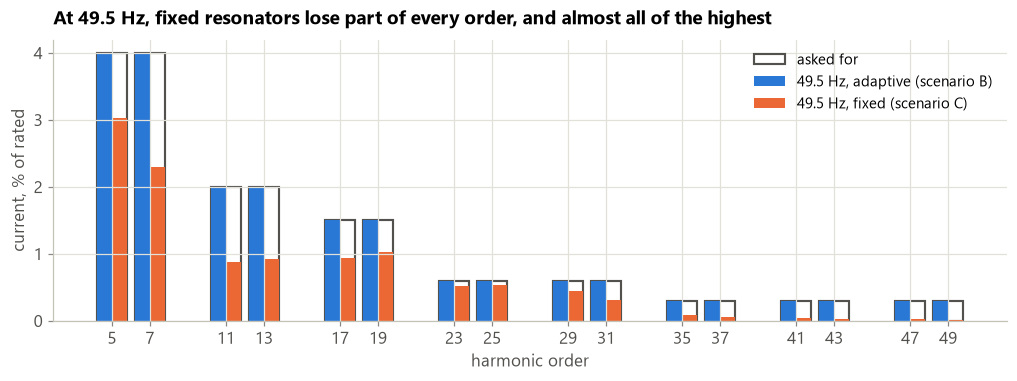

In [3]:
s = A.load("scenarios_hil404.csv")
fig, ax = A.panels(1, h=3.6)
b = s[(s.scenario == "B") & (s.order > 1)]; c = s[(s.scenario == "C") & (s.order > 1)]
ax[0].bar(b.order, b.I_request_pct, 1.6, color="none", edgecolor=A.LIMIT, lw=1.4, label="asked for")
ax[0].bar(b.order - 0.4, b.I_pct, 0.8, color=A.USED, label="49.5 Hz, adaptive (scenario B)")
ax[0].bar(c.order + 0.4, c.I_pct, 0.8, color=A.OTHER, label="49.5 Hz, fixed (scenario C)")
A.orders_axis(ax[0]); ax[0].set_ylabel("current, % of rated"); ax[0].legend()
ax[0].set_title("At 49.5 Hz, fixed resonators lose part of every order, and almost all of the highest")
A.save(fig, "05_orders_49p5", pd.concat([b.assign(case="B adaptive"), c.assign(case="C fixed")]))

**Reading.** The miss at order h is h × 0.5 Hz (24.5 Hz at the 49th). Every order loses something;
the 35th-49th are almost entirely lost. The loss is not a smooth function of order, because the orders
interact through the shared controller. With adaptive resonators (blue) every order is delivered.

## Limits of this notebook
- Tested 49-51 Hz in steady state. Fast frequency changes (ramps, steps) were not tested.

In [4]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C5.1 | Adaptive resonators, 49-51 Hz (HIL404): worst order error at most | 0.17 % | results/sweep_hil404_points.csv (sweep 'freq') |
| C5.2 | Fixed resonators, any frequency 0.25 Hz or more off 50 Hz (HIL404): worst order error | 89-97 % | same file |
| C5.3 | Fixed resonators: delivered total harmonic current ranges from (49 Hz) to (51 Hz) | 2.9 % to 7.7 % (asked 6.82 %) | same file |